<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-016-pca-tsne-clustering.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
**Author:** Marcin Płodzień <br>
**Lab:** 016 &nbsp;·&nbsp; **Lecture:** 5 (*Unsupervised learning*)
<hr/>

# Lab 016 — PCA, t-SNE and clustering, written in JAX

Until now every image came with a label, and a network learned to predict it. Here we keep only the data, $\{\mathbf x_i\}_{i=1}^{n}$, and ask what can be learned without labels: which few variables describe a sample, and whether the samples form groups.

The notebook follows the lecture:

1. **High-dimensional data.** An MNIST image is a point in $\mathbb R^{784}$, but the digits fill only a thin part of that space.
2. **Principal component analysis (PCA).** A linear projection; we derive it from variance maximisation and compute it by hand with `jnp.linalg.eigh` and `jnp.linalg.svd`.
3. **t-SNE.** A non-linear map that keeps neighbours. We write the whole algorithm ourselves: the per-point bandwidths by a vectorised binary search, the gradient of the Kullback–Leibler loss (checked against automatic differentiation), and a compiled optimisation loop.
4. **Clustering.** k-means with k-means++ initialisation, the silhouette score and the elbow to choose $k$, the Rand and adjusted Rand indices to compare clusterings with known classes, and DBSCAN for clusters of arbitrary shape.

Every algorithm is implemented from its equations in JAX. The labels of the digits are used **only to colour points and to score** a result after a method has run. All random numbers come from explicit JAX keys, so a rerun gives the same numbers. The figures of the lecture slides are written to `../beamer/figures/`, and the numbers quoted on the slides are collected in the dictionary `nums` and saved at the end.

Each part ends with a **Try it** exercise.

> **How to run this notebook**
> 1. Run the cells in order (**Shift + Enter**); later cells use functions and arrays defined earlier.
> 2. The notebook runs on the CPU (the first code cell sets `JAX_PLATFORMS=cpu`). The exact t-SNE maps of 5000 points take the longest; every t-SNE cell prints its running time. In Colab it runs as it is; with a GPU runtime one may delete the `JAX_PLATFORMS` line.
> 3. Required packages: `jax`, `numpy`, `matplotlib`. In Google Colab they are pre-installed. `scikit-learn` is used only in one optional cross-check cell at the end.
> 4. The MNIST files (about 11 MB) are read from `data/MNIST_raw`; if they are missing they are downloaded there once.

## Setup

Two settings:

* `JAX_PLATFORMS="cpu"` must be set **before** `import jax`, because JAX chooses its device when it starts. All computations here run on the CPU; XLA uses all its cores.
* `jax_default_matmul_precision="highest"`: on GPUs a float32 matrix product may by default be computed with reduced internal precision (TF32, about 3 significant digits). On a CPU the setting changes nothing; it is kept so that covariance matrices and distances have full float32 accuracy on any device.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # run everything on the CPU

import gzip, json, time, urllib.request
from collections import deque
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from jax import lax

jax.config.update("jax_default_matmul_precision", "highest")
print("JAX", jax.__version__, "| devices:", jax.devices())

import os

OUT = "figures"; os.makedirs(OUT, exist_ok=True)                      # the figures of the lecture slides
os.makedirs(OUT, exist_ok=True)
blue, orange, navy = "#005CA7", "#EB6709", "#0A2F5C"
purple, green = "#9467bd", "#2ca02c"
cmap = plt.get_cmap("tab10")
nums = {}                                      # numbers quoted on the slides
T0 = time.time()
def log(msg): print(f"[{time.time() - T0:6.1f} s] {msg}", flush=True)

def clean(ax):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

def save(name):
    plt.savefig(f"{OUT}/{name}", dpi=170, bbox_inches="tight")

ROOT = jax.random.key(0)                       # the one master key of this notebook
def section_key(i):
    # an independent key for part i; rerunning a cell always gives the same random numbers
    return jax.random.fold_in(ROOT, i)

JAX 0.11.0 | devices: [CpuDevice(id=0)]


### JAX in a nutshell

JAX looks like NumPy (`jnp.sum`, `jnp.linalg.eigh`, `x @ y`, ...) but adds four ideas used throughout this notebook. Each is explained again where it first appears.

* **Arrays are immutable.** `x[0] = 1` is not allowed; one writes `x = x.at[0].set(1)`, which returns a new array. Functions are *pure*: the output depends only on the inputs.
* **Explicit random keys.** There is no hidden global random state. A *key* is a small array; `jax.random.normal(key, shape)` always returns the same numbers for the same key. New independent keys are made with `jax.random.split(key)` or `jax.random.fold_in(key, i)`. Above, `section_key(i)` gives every part of the notebook its own key.
* **`jax.jit`** compiles a function with XLA the first time it is called with arrays of a given shape (the *trace*); later calls with the same shapes run the compiled code. Arguments that change the program itself (a number of clusters, a number of iterations) are declared `static`.
* **`jax.vmap`** turns a function written for one example into a function for a batch, without a Python loop. `lax.fori_loop`, `lax.scan` and `lax.while_loop` are loops that live *inside* the compiled program.

JAX executes asynchronously: a call returns before the computation has finished. To time a computation we call `.block_until_ready()`. To plot, arrays are moved to the host with `np.asarray(x)`.

## 1. High-dimensional data

A $28\times28$ MNIST image is a vector $\mathbf x\in\mathbb R^{784}$, one coordinate per pixel. We cannot look at 784 dimensions. But real images are not spread over all of $\mathbb R^{784}$: 784 random pixel values give noise, never a digit. The digits fill a thin, low-dimensional part of the space.

Analysis of such data therefore usually starts with **dimensionality reduction**: a map $\mathbf x\in\mathbb R^{D}\mapsto\mathbf z\in\mathbb R^{d}$ with $d\ll D$ (here $d=2$ or $3$, so that we can plot it) that keeps the structure of the data. We then look at the points $\mathbf z_i$: do they form groups, which samples are close?

The MNIST files have a simple binary format (*idx*): a 4-byte *magic number* whose last byte is the number of dimensions, then the size of each dimension as a 4-byte big-endian integer, then the raw `uint8` values. We decode it with `gzip` and `numpy` and scale the pixels to $[0,1]$.

In [2]:
DATA_DIR = "data/MNIST_raw"
MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/",
           "https://storage.googleapis.com/cvdf-datasets/mnist/"]

def mnist_file(name):
    # path of one MNIST file; downloaded once if it is not on disk
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        os.makedirs(DATA_DIR, exist_ok=True)
        for m in MIRRORS:
            try:
                urllib.request.urlretrieve(m + name, path); break
            except Exception as err:
                print(f"{m} failed: {err}")
    return path

def read_idx(path):
    with gzip.open(path, "rb") as f:
        raw = f.read()
    ndim = raw[3]                                            # last byte of the magic number
    shape = np.frombuffer(raw, dtype=">i4", count=ndim, offset=4)
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * ndim).reshape(shape)

Xtr = jnp.asarray(read_idx(mnist_file("train-images-idx3-ubyte.gz")).reshape(-1, 784), jnp.float32) / 255.0
ytr = np.asarray(read_idx(mnist_file("train-labels-idx1-ubyte.gz")))
Xte = jnp.asarray(read_idx(mnist_file("t10k-images-idx3-ubyte.gz")).reshape(-1, 784), jnp.float32) / 255.0
yte = np.asarray(read_idx(mnist_file("t10k-labels-idx1-ubyte.gz")))

# 5000 test images for all maps; the labels only colour the points afterwards
sel = np.asarray(jax.random.choice(section_key(1), len(Xte), (5000,), replace=False))
X5, y5 = Xte[sel], yte[sel]
print("training images:", Xtr.shape, "| test images:", Xte.shape, "| subset for the maps:", X5.shape)

training images: (60000, 784) | test images: (10000, 784) | subset for the maps: (5000, 784)


Ten digits of the subset, and a "random image" with 784 independent uniform pixel values. The random image is a perfectly valid point of $\mathbb R^{784}$, yet nothing like it appears among the digits.

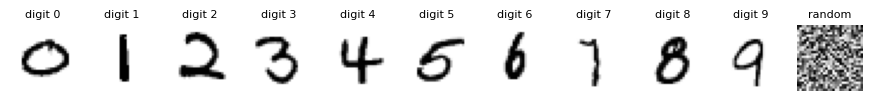

In [3]:
fig, axs = plt.subplots(1, 11, figsize=(11, 1.4))
for j, a in enumerate(axs[:10]):
    i = int(np.flatnonzero(y5 == j)[0])
    a.imshow(np.asarray(X5[i]).reshape(28, 28), cmap="gray_r"); a.set_title(f"digit {j}", fontsize=8)
noise = jax.random.uniform(section_key(2), (784,))
axs[10].imshow(np.asarray(noise).reshape(28, 28), cmap="gray_r"); axs[10].set_title("random", fontsize=8)
for a in axs: a.axis("off")
plt.show()

## 2. Principal component analysis

PCA is a **linear** projection. The data are $n$ samples $\mathbf x_1,\dots,\mathbf x_n\in\mathbb R^D$ with mean $\bar{\mathbf x}=\frac1n\sum_i\mathbf x_i$. We write $x_{ij}$ for feature $j$ (pixel $j$) of sample $i$. The **covariance matrix** of the features is the $D\times D$ matrix

$$C_{jl}=\frac1n\sum_{i=1}^{n}(x_{ij}-\bar x_j)(x_{il}-\bar x_l),\qquad C=\frac1n X_c^{\top}X_c ,$$

with $X_c$ the $n\times D$ matrix of centred samples. $C_{jj}$ is the variance of pixel $j$; $C_{jl}$ says how pixels $j$ and $l$ vary together.

### Variance maximisation leads to an eigenproblem

Project every centred sample on a unit vector $\mathbf u$: $z_i=\mathbf u\cdot(\mathbf x_i-\bar{\mathbf x})$. The variance of the projections is

$$\mathrm{Var}(z)=\frac1n\sum_i z_i^2=\frac1n\sum_i \mathbf u^{\top}(\mathbf x_i-\bar{\mathbf x})(\mathbf x_i-\bar{\mathbf x})^{\top}\mathbf u=\mathbf u^{\top}C\,\mathbf u .$$

We look for the direction of **largest** variance: maximise $\mathbf u^{\top}C\mathbf u$ subject to $\mathbf u^{\top}\mathbf u=1$. With a Lagrange multiplier $\lambda$,

$$\frac{\partial}{\partial\mathbf u}\Big[\mathbf u^{\top}C\mathbf u-\lambda(\mathbf u^{\top}\mathbf u-1)\Big]=2C\mathbf u-2\lambda\mathbf u=0\quad\Longrightarrow\quad C\mathbf u=\lambda\mathbf u .$$

The stationary directions are the eigenvectors of $C$, and at an eigenvector the variance is $\mathbf u^{\top}C\mathbf u=\lambda$. So the best direction is the eigenvector with the largest eigenvalue. Repeating the argument with the extra constraint that $\mathbf u$ is orthogonal to the directions already found gives the next eigenvectors in order.

$C$ is symmetric and positive semi-definite, so it has $D$ orthonormal eigenvectors $C\mathbf v_a=\lambda_a\mathbf v_a$ with $\lambda_1\ge\lambda_2\ge\dots\ge\lambda_D\ge 0$. The leading $m$ eigenvectors are the **principal components**, and the projection is

$$z_{ia}=\mathbf v_a\cdot(\mathbf x_i-\bar{\mathbf x}),\qquad a=1,\dots,m,\qquad \text{fraction of variance kept}=\frac{\sum_{a\le m}\lambda_a}{\sum_{a\le D}\lambda_a}.$$

The same subspace also minimises the mean squared **reconstruction** error $\frac1n\sum_i\lVert\mathbf x_i-\bar{\mathbf x}-\sum_{a\le m}z_{ia}\mathbf v_a\rVert^2=\sum_{a>m}\lambda_a$: keeping the largest eigenvalues throws away the least.

**Relation to the SVD.** Write $X_c=USV^{\top}$ (singular value decomposition). Then $C=\frac1n VS^2V^{\top}$: the right singular vectors are the principal components and $\lambda_a=s_a^2/n$. Both routes are used below.

*Conventions.* scikit-learn divides by $n-1$ instead of $n$; this rescales all eigenvalues by the same factor and changes neither the eigenvectors nor the fractions of variance. The sign of each eigenvector is arbitrary; we fix it so that its largest entry (in absolute value) is positive.

### PCA, by hand, in JAX

The function `pca` below is decorated with `@jax.jit`. The first call traces it and compiles it for the given array shape; the next call with the same shape reuses the compiled code. `jnp.linalg.eigh` diagonalises a symmetric matrix and returns the eigenvalues in **increasing** order, so we reverse them.

In [4]:
@jax.jit
def covariance(X):
    xbar = X.mean(axis=0)
    Xc = X - xbar
    return xbar, Xc.T @ Xc / X.shape[0]

def fix_signs(V):
    # make the largest-|entry| of every column positive (the sign of an eigenvector is arbitrary)
    idx = jnp.argmax(jnp.abs(V), axis=0)
    return V * jnp.sign(V[idx, jnp.arange(V.shape[1])])

@jax.jit
def pca(X):
    # mean, eigenvalues (largest first) and eigenvectors (columns) of the covariance matrix
    xbar, C = covariance(X)
    lam, V = jnp.linalg.eigh(C)
    return xbar, lam[::-1], fix_signs(V[:, ::-1])

First a two-dimensional cloud of 400 correlated Gaussian points. `jax.random.multivariate_normal` takes a key, a mean and a covariance.

The cell also checks the variance-maximisation argument numerically: we compute $\mathrm{Var}(z)=\mathbf u(\theta)^{\top}C\,\mathbf u(\theta)$ for 721 unit vectors $\mathbf u(\theta)=(\cos\theta,\sin\theta)$. The function `var_along` is written for **one** angle; `jax.vmap(var_along)` evaluates it for the whole array of angles at once (it adds a batch dimension to every operation, instead of a Python loop).

eigenvalues: [3.56 0.25] | fraction of the variance: [0.934, 0.066]


largest variance over the angles: 3.5604 at theta = 0.537 | lambda_1 = 3.5604, direction of v_1: theta = 0.535


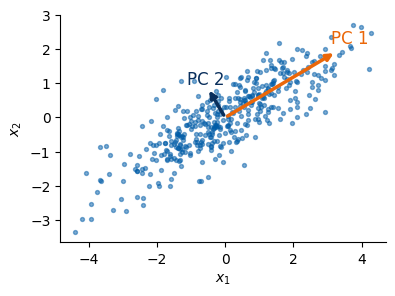

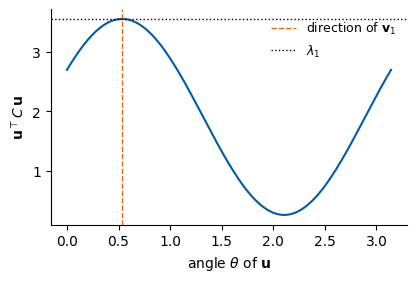

In [5]:
pts = jax.random.multivariate_normal(section_key(3), jnp.zeros(2), jnp.array([[3.0, 1.6], [1.6, 1.2]]), (400,))
xbar_t, lam_t, V_t = pca(pts)
ratio_t = lam_t / lam_t.sum()
nums["pca_toy_var"] = [round(float(r), 3) for r in ratio_t]
print("eigenvalues:", np.round(np.asarray(lam_t), 3), "| fraction of the variance:", nums["pca_toy_var"])

_, C_t = covariance(pts)
def var_along(theta):
    u = jnp.array([jnp.cos(theta), jnp.sin(theta)])
    return u @ C_t @ u
thetas = jnp.linspace(0, jnp.pi, 721)
var_theta = jax.vmap(var_along)(thetas)
theta_pc1 = jnp.arctan2(V_t[1, 0], V_t[0, 0]) % jnp.pi
print(f"largest variance over the angles: {float(var_theta.max()):.4f} at theta = {float(thetas[jnp.argmax(var_theta)]):.3f}"
      f" | lambda_1 = {float(lam_t[0]):.4f}, direction of v_1: theta = {float(theta_pc1):.3f}")

# figure for the slides: the cloud and its principal axes
P_ = np.asarray(pts - xbar_t)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.scatter(P_[:, 0], P_[:, 1], s=8, color=blue, alpha=0.5)
for a_, c, name in zip(range(2), [orange, navy], ["PC 1", "PC 2"]):
    v = np.asarray(V_t[:, a_]); L_ = float(lam_t[a_])
    ax.annotate("", xy=2 * np.sqrt(L_) * v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.5))
    ax.text(*(2.25 * np.sqrt(L_) * v), name, color=c, fontsize=12, ha="center")
ax.set_aspect("equal"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); clean(ax)
save("gen_pca_toy.png"); plt.show()

fig, ax = plt.subplots(figsize=(4.6, 2.8))
ax.plot(np.asarray(thetas), np.asarray(var_theta), color=blue)
ax.axvline(float(theta_pc1), color=orange, ls="--", lw=1, label=r"direction of $\mathbf{v}_1$")
ax.axhline(float(lam_t[0]), color="k", ls=":", lw=1, label=r"$\lambda_1$")
ax.set_xlabel(r"angle $\theta$ of $\mathbf{u}$"); ax.set_ylabel(r"$\mathbf{u}^\top C\,\mathbf{u}$"); ax.legend(frameon=False, fontsize=9); clean(ax)
plt.show()

### PCA on MNIST

The same computation on the 60 000 training images: $C$ is $784\times784$, and its leading eigenvectors are themselves $28\times28$ images (red and blue: positive and negative weights). We then compute the same eigenvalues a second way, from the SVD of the centred $60000\times784$ data matrix, and compare.

variance kept by 2, 3, 10, 50 components: [0.168, 0.23, 0.488, 0.825] | components needed for 90%: 87


largest relative difference of the first 50 eigenvalues (eigh vs SVD): 2.4e-05


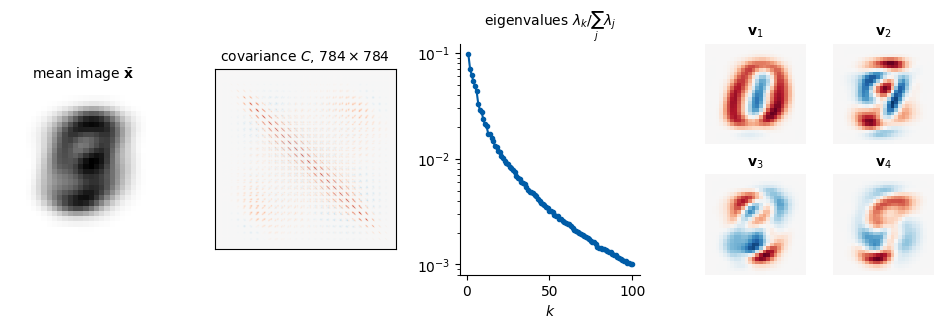

In [6]:
xbar, lam, V = pca(Xtr)
_, C = covariance(Xtr)
frac = jnp.cumsum(lam) / lam.sum()                 # fraction of the variance kept by the first m components
nums["mnist_pca_var2"]  = float(frac[1])
nums["mnist_pca_var3"]  = float(frac[2])
nums["mnist_pca_var10"] = float(frac[9])
nums["mnist_pca_var50"] = float(frac[49])
nums["mnist_pca_frac_2_10_50"] = [round(float(frac[m - 1]), 3) for m in (2, 10, 50)]
nums["mnist_pca_k_for_90"] = int(jnp.searchsorted(frac, 0.90) + 1)
print("variance kept by 2, 3, 10, 50 components:", [round(float(frac[m - 1]), 3) for m in (2, 3, 10, 50)],
      "| components needed for 90%:", nums["mnist_pca_k_for_90"])

# the same eigenvalues from the SVD of the centred data
s = jnp.linalg.svd(Xtr - xbar, compute_uv=False)
lam_svd = s ** 2 / Xtr.shape[0]
print("largest relative difference of the first 50 eigenvalues (eigh vs SVD):",
      f"{float(jnp.max(jnp.abs(lam_svd[:50] - lam[:50]) / lam[:50])):.1e}")

lam_np, V_np, C_np = np.asarray(lam), np.asarray(V), np.asarray(C)
fig = plt.figure(figsize=(12, 3.0))
gs = fig.add_gridspec(2, 8, width_ratios=[1.3, 0.25, 1.6, 0.3, 1.6, 0.25, 1, 1], wspace=0.15, hspace=0.3)
a = fig.add_subplot(gs[:, 0]); a.imshow(np.asarray(xbar).reshape(28, 28), cmap="gray_r")
a.set_title(r"mean image $\bar{\mathbf{x}}$", fontsize=10); a.axis("off")
a = fig.add_subplot(gs[:, 2]); vm = np.abs(C_np).max(); a.imshow(C_np, cmap="RdBu_r", vmin=-vm, vmax=vm)
a.set_title(r"covariance $C$, $784\times784$", fontsize=10); a.set_xticks([]); a.set_yticks([])
a = fig.add_subplot(gs[:, 4]); a.semilogy(np.arange(1, 101), lam_np[:100] / lam_np.sum(), ".-", color=blue)
a.set_title(r"eigenvalues $\lambda_k/\sum_j\lambda_j$", fontsize=10); a.set_xlabel("$k$"); clean(a)
for j in range(4):
    a = fig.add_subplot(gs[j // 2, 6 + j % 2]); w = V_np[:, j]; m = np.abs(w).max()
    a.imshow(w.reshape(28, 28), cmap="RdBu_r", vmin=-m, vmax=m); a.set_title(rf"$\mathbf{{v}}_{j+1}$", fontsize=10); a.axis("off")
save("gen_pca_mnist_steps.png"); plt.show()

### Reconstruction from a few components

An image is rebuilt from its first $m$ projections as $\hat{\mathbf x}=\bar{\mathbf x}+\sum_{a\le m}z_a\mathbf v_a$. With all 784 components the reconstruction is exact; with few components only the coarse shape survives. The column titles give $m$. The printout compares, for each $m$, the mean squared reconstruction error per pixel on the 5000 test images with $\frac1{784}\sum_{a>m}\lambda_a$; the two agree exactly on the training data and closely on the test data.

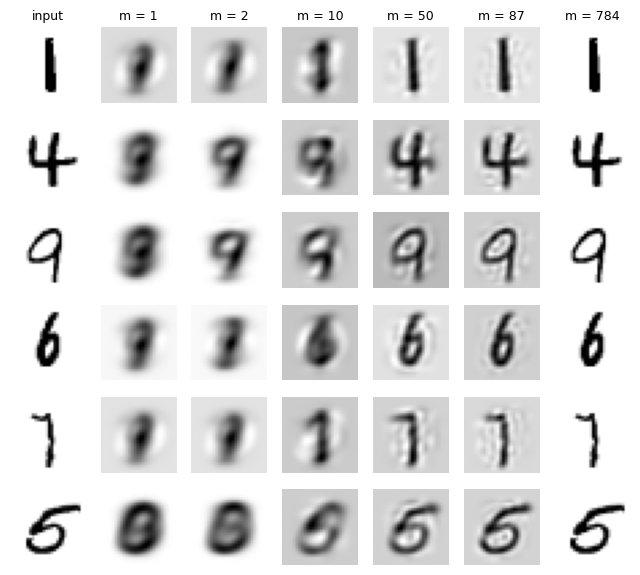

m =   1: test MSE per pixel 0.06078 | discarded eigenvalues / 784: 0.06072


m =   2: test MSE per pixel 0.05576 | discarded eigenvalues / 784: 0.05595


m =  10: test MSE per pixel 0.03422 | discarded eigenvalues / 784: 0.03442


m =  50: test MSE per pixel 0.01157 | discarded eigenvalues / 784: 0.01179


m =  87: test MSE per pixel 0.00661 | discarded eigenvalues / 784: 0.00672


m = 784: test MSE per pixel 0.00000 | discarded eigenvalues / 784: 0.00000


In [7]:
ms = [1, 2, 10, 50, nums["mnist_pca_k_for_90"], 784]
show = X5[:6]
fig, axs = plt.subplots(len(show), len(ms) + 1, figsize=(8, 7))
for r in range(len(show)):
    axs[r, 0].imshow(np.asarray(show[r]).reshape(28, 28), cmap="gray_r")
    for c, m in enumerate(ms):
        Vm = V[:, :m]
        rec = xbar + ((show[r] - xbar) @ Vm) @ Vm.T
        axs[r, c + 1].imshow(np.asarray(rec).reshape(28, 28), cmap="gray_r")
axs[0, 0].set_title("input", fontsize=9)
for c, m in enumerate(ms): axs[0, c + 1].set_title(f"m = {m}", fontsize=9)
for a in axs.ravel(): a.axis("off")
plt.show()
for m in ms:
    Vm = V[:, :m]
    err = jnp.mean((X5 - xbar - ((X5 - xbar) @ Vm) @ Vm.T) ** 2)
    print(f"m = {m:3d}: test MSE per pixel {float(err):.5f} | discarded eigenvalues / 784: {float(lam[m:].sum() / 784):.5f}")

### Projection on the first components

The 5000 test images projected on the 50 leading components; the first two are plotted. Left: what PCA sees (no labels). Right: the same points coloured by the true digit.

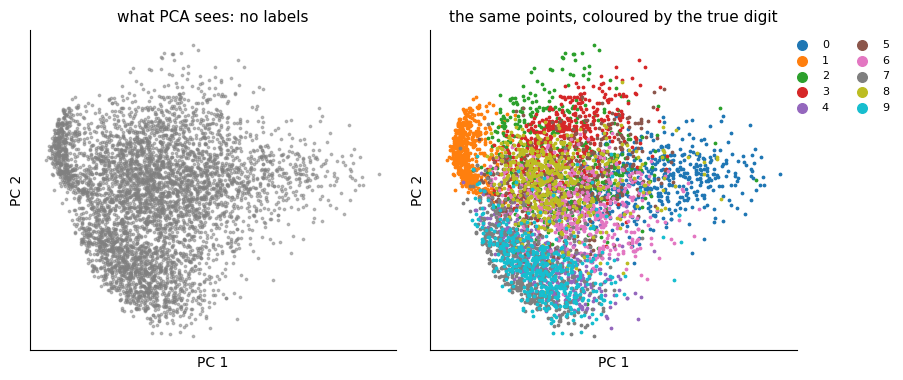

{'mnist_pca_var2': 0.168, 'mnist_pca_var3': 0.23, 'mnist_pca_var50': 0.825}
[  19.8 s] PCA done


In [8]:
Z = (X5 - xbar) @ V[:, :50]                        # 5000 x 50: the input of t-SNE and k-means below
Zn = np.asarray(Z)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
axs[0].scatter(Zn[:, 0], Zn[:, 1], s=3, color="grey", alpha=0.5)
axs[0].set_title("what PCA sees: no labels", fontsize=11)
for d in range(10):
    m = y5 == d; axs[1].scatter(Zn[m, 0], Zn[m, 1], s=3, color=cmap(d), label=str(d))
axs[1].set_title("the same points, coloured by the true digit", fontsize=11)
axs[1].legend(markerscale=4, fontsize=8, ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(1.28, 1))
for a in axs: a.set_xlabel("PC 1"); a.set_ylabel("PC 2"); a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); save("gen_pca_mnist.png"); plt.show()
print({k: round(nums[k], 3) for k in ["mnist_pca_var2", "mnist_pca_var3", "mnist_pca_var50"]})
log("PCA done")

### Three components

The projection on the first three principal components, from two viewing angles.

/tmp/ipykernel_4070283/2151283050.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); save("gen_pca_mnist_3d.png"); plt.show()


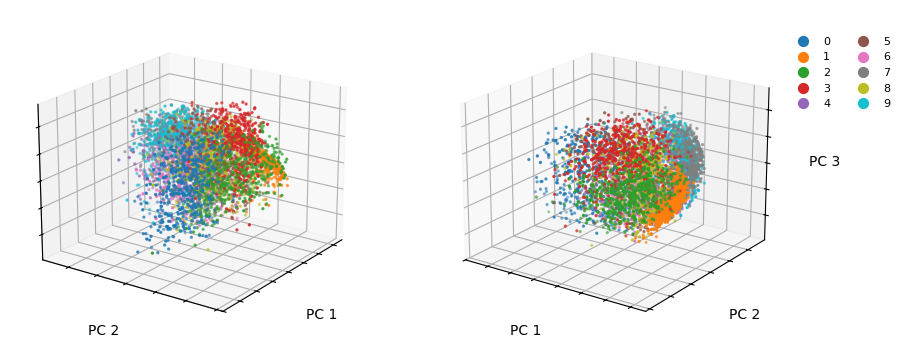

variance kept by 3 components: 0.23


In [9]:
fig = plt.figure(figsize=(10, 4.4))
for k_, (elev, azim) in enumerate([(20, 35), (20, 125)]):
    a = fig.add_subplot(1, 2, k_ + 1, projection="3d")
    for dgt in range(10):
        m = y5 == dgt
        a.scatter(Zn[m, 0], Zn[m, 1], Zn[m, 2], s=2, color=cmap(dgt), label=str(dgt))
    a.view_init(elev=elev, azim=azim)
    a.set_xlabel("PC 1"); a.set_ylabel("PC 2"); a.set_zlabel("PC 3")
    a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
a.legend(markerscale=5, fontsize=8, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 0.95))
plt.tight_layout(); save("gen_pca_mnist_3d.png"); plt.show()
print("variance kept by 3 components:", round(nums["mnist_pca_var3"], 3))

**Try it.**
* Plot PC 1 against PC 3, or PC 2 against PC 3. Which digits separate along which component? Compare with the eigenvector images $\mathbf v_a$.
* Run PCA on the images of a single digit (e.g. `Xtr[ytr == 1]`). What do the first eigenvectors describe now (slant, width, ...)?
* Standardise every pixel (divide by its standard deviation, skipping pixels that are always zero) before PCA, i.e. diagonalise the correlation matrix. How does the fraction of variance kept by 50 components change, and why is this not a good idea for images?

## 3. t-SNE

PCA keeps the directions of largest variance, but a linear projection to 2D squeezes curved structure together. t-SNE (van der Maaten & Hinton, J. Mach. Learn. Res. **9**, 2579 (2008)) asks for something different: **points that are neighbours in $\mathbb R^{D}$ should be neighbours in the map.**

**Similarities in the data.** Around each point $\mathbf x_i$ put a Gaussian of width $\sigma_i$ and turn the squared distances $d_{ij}^2=\lVert\mathbf x_i-\mathbf x_j\rVert^2$ into a probability over the $n-1$ other points:

$$p_{j|i}=\frac{\exp(-d_{ij}^2/2\sigma_i^2)}{\sum_{l\ne i}\exp(-d_{il}^2/2\sigma_i^2)},\qquad p_{i|i}=0,\qquad p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n}.$$

The symmetrised $p_{ij}$ sum to one over all pairs. Each $\sigma_i$ is chosen so that the distribution $P_i=(p_{j|i})_j$ has a prescribed **perplexity**

$$\mathrm{Perp}(P_i)=e^{H(P_i)},\qquad H(P_i)=-\sum_j p_{j|i}\ln p_{j|i},$$

an effective number of neighbours. ($e^{H}$ with the natural logarithm equals $2^{H}$ with $H$ in bits, the form used in the paper.) A point in a dense region gets a small $\sigma_i$, a point in a sparse region a large one.

**Similarities in the map.** For the map points $\mathbf z_i\in\mathbb R^{d}$ use a Student-t kernel with one degree of freedom (a Cauchy distribution):

$$q_{ij}=\frac{w_{ij}}{\sum_{l\ne m}w_{lm}},\qquad w_{ij}=\big(1+\lVert\mathbf z_i-\mathbf z_j\rVert^2\big)^{-1},\qquad q_{ii}=0 .$$

**Loss.** Move the $\mathbf z_i$ by gradient descent so that $Q$ approaches $P$:

$$\mathcal L(\mathbf z_1,\dots,\mathbf z_n)=\mathrm{KL}(P\,\|\,Q)=\sum_{i\ne j}p_{ij}\ln\frac{p_{ij}}{q_{ij}} .$$

Neighbours placed far apart ($p_{ij}$ large, $q_{ij}$ small) cost a lot; distant points placed close ($p_{ij}$ small) cost little. t-SNE therefore keeps the **local** structure.

**Gradient.** Write $\mathcal L=\text{const}-\sum_{i\ne j}p_{ij}\ln w_{ij}+\ln\sum_{l\ne m}w_{lm}$ (using $\sum p_{ij}=1$) and use $\partial w_{ij}/\partial\mathbf z_i=-2w_{ij}^2(\mathbf z_i-\mathbf z_j)$. Both terms combine into

$$\frac{\partial\mathcal L}{\partial\mathbf z_i}=4\sum_{j}\,(p_{ij}-q_{ij})\,w_{ij}\,(\mathbf z_i-\mathbf z_j) .$$

A pair with $p_{ij}>q_{ij}$ pulls $\mathbf z_i$ towards $\mathbf z_j$ (attraction), a pair with $p_{ij}<q_{ij}$ pushes it away (repulsion).

**The Student-t in the map.** In 784 dimensions a point can have many neighbours at similar distances; in 2D there is no room for all of them (the *crowding problem*). The heavy tail of the Student-t lets moderately distant points sit far apart in the map, which opens gaps between groups.

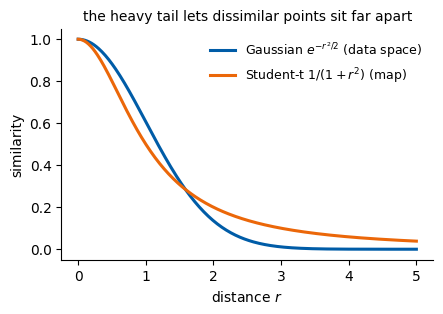

In [10]:
r = np.linspace(0, 5, 300)
fig, ax = plt.subplots(figsize=(4.8, 3.0))
ax.plot(r, np.exp(-r**2 / 2), color=blue, lw=2.2, label=r"Gaussian $e^{-r^2/2}$ (data space)")
ax.plot(r, 1 / (1 + r**2), color=orange, lw=2.2, label=r"Student-t $1/(1+r^2)$ (map)")
ax.set_xlabel("distance $r$"); ax.set_ylabel("similarity"); ax.legend(frameon=False, fontsize=9); clean(ax)
ax.set_title("the heavy tail lets dissimilar points sit far apart", fontsize=10)
save("gen_tsne_kernels.png"); plt.show()

### Step 1: the bandwidths $\sigma_i$ by a vectorised binary search

The entropy $H(P_i)$ decreases monotonically with the *precision* $\beta_i=1/2\sigma_i^2$, so for every point we find $\beta_i$ by bisection until $H(P_i)=\ln(\mathrm{Perp})$. We bisect in $\ln\beta$ (the scale of $\beta$ is unknown), 64 halvings of the interval $[-23,23]$.

JAX idioms in the next cell:

* **Squared distances by the Gram trick.** $\lVert\mathbf x_i-\mathbf x_j\rVert^2=\lVert\mathbf x_i\rVert^2+\lVert\mathbf x_j\rVert^2-2\,\mathbf x_i\cdot\mathbf x_j$: one matrix product instead of an $n\times n\times D$ array of differences. Tiny negative values from rounding are clipped to zero.
* **`lax.fori_loop(lo, hi, body, init)`** runs `body(i, state)` for `i = lo, ..., hi-1` inside the compiled program. The state here is the pair of interval ends.
* **`jax.vmap(one_row)`** runs the bisection for all $n$ rows at once. `one_row` is written for a single point; vmap supplies its row of distances and its index.
* `jax.nn.log_softmax` computes $\ln p_{j|i}$ stably (it subtracts the largest logit before exponentiating). The point itself is excluded by setting its logit to $-\infty$.

In [11]:
@jax.jit
def sq_dists(X):
    # matrix of squared Euclidean distances, via the Gram matrix (good for many features)
    s = jnp.sum(X * X, axis=1)
    return jnp.maximum(s[:, None] + s[None, :] - 2.0 * X @ X.T, 0.0)

def sq_dists_lowdim(Y):
    # the same for a map with d = 1, 2 or 3 coordinates: exact differences, one coordinate at a time
    # (a Python loop over the d coordinates is unrolled when the function is traced)
    return sum((Y[:, None, a] - Y[None, :, a]) ** 2 for a in range(Y.shape[1]))

def conditional_p(D2, perplexity, n_steps=64):
    # rows p_{j|i} with the prescribed perplexity, and the precisions beta_i = 1 / (2 sigma_i^2)
    n = D2.shape[0]
    target = jnp.log(perplexity)

    def one_row(d_row, i):
        mask = jnp.arange(n) != i                              # exclude j = i

        def p_and_entropy(log_beta):
            logits = jnp.where(mask, -jnp.exp(log_beta) * d_row, -jnp.inf)
            logp = jax.nn.log_softmax(logits)
            p = jnp.exp(logp)
            return p, -jnp.sum(jnp.where(mask, p * logp, 0.0))

        def bisect(_, bounds):
            lo, hi = bounds
            mid = 0.5 * (lo + hi)
            too_wide = p_and_entropy(mid)[1] > target           # entropy too large: increase beta
            return jnp.where(too_wide, mid, lo), jnp.where(too_wide, hi, mid)

        lo, hi = lax.fori_loop(0, n_steps, bisect, (jnp.float32(-23.0), jnp.float32(23.0)))
        log_beta = 0.5 * (lo + hi)
        return p_and_entropy(log_beta)[0], jnp.exp(log_beta)

    return jax.vmap(one_row)(D2, jnp.arange(n))

@jax.jit
def joint_p(X, perplexity):
    # symmetrised p_ij (sums to 1) and the bandwidths sigma_i
    n = X.shape[0]
    Pc, beta = conditional_p(sq_dists(X), perplexity)
    P = (Pc + Pc.T) / (2.0 * n)
    return jnp.maximum(P, 1e-12), jnp.sqrt(1.0 / (2.0 * beta))

A check on the 5000 digits (in their 50 PCA coordinates, as is common: faster, and the noise of the last components is removed). We recompute the perplexity of every row from the $p_{j|i}$ that come out of the search; all rows should hit the target.

binary search for 5000 points: 6.84 s (including compilation)
achieved perplexity: min 30.000, max 30.000 (target 30)
sigma_i: min 0.619, median 1.451, max 2.263


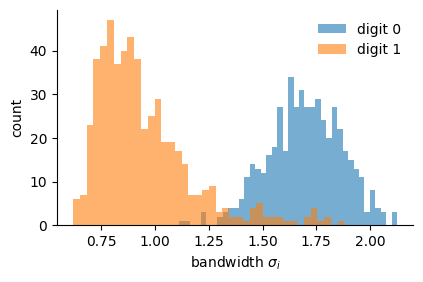

In [12]:
t = time.time()
Pc_chk, beta_chk = jax.jit(conditional_p)(sq_dists(Z), 30.0)
Pc_chk.block_until_ready()
H_chk = -jnp.sum(jnp.where(Pc_chk > 0, Pc_chk * jnp.log(jnp.where(Pc_chk > 0, Pc_chk, 1.0)), 0.0), axis=1)
perp_chk = jnp.exp(H_chk)
sig_chk = np.asarray(jnp.sqrt(1 / (2 * beta_chk)))
print(f"binary search for 5000 points: {time.time() - t:.2f} s (including compilation)")
print(f"achieved perplexity: min {float(perp_chk.min()):.3f}, max {float(perp_chk.max()):.3f} (target 30)")
print(f"sigma_i: min {sig_chk.min():.3f}, median {np.median(sig_chk):.3f}, max {sig_chk.max():.3f}")

fig, ax = plt.subplots(figsize=(4.6, 2.8))
for d in [0, 1]:
    ax.hist(sig_chk[y5 == d], bins=40, alpha=0.6, color=cmap(d), label=f"digit {d}")
ax.set_xlabel(r"bandwidth $\sigma_i$"); ax.set_ylabel("count"); ax.legend(frameon=False); clean(ax)
plt.show()

The 1s are simple strokes that lie close to each other; at the same perplexity they get smaller bandwidths than the 0s. This is how $\sigma_i$ adapts to the local density.

### Step 2: the gradient, checked against automatic differentiation

We implement the gradient formula derived above, and check it against `jax.grad` of the loss on 300 points. `jax.grad(f)` returns a new function that computes $\partial f/\partial(\text{first argument})$ by reverse-mode automatic differentiation. Agreement to float32 precision confirms the hand derivation.

The factor `exag` multiplies $P$ during the first iterations (*early exaggeration*, explained in step 3); it is 1 for the plain gradient.

In [13]:
def tsne_grad_kl(P, Y, exag):
    # analytic gradient of KL(exag * P || Q) w.r.t. the map points Y (n x d), and KL(P || Q)
    n = Y.shape[0]
    W = 1.0 / (1.0 + sq_dists_lowdim(Y))
    W = W.at[jnp.diag_indices(n)].set(0.0)                 # w_ii = 0 (functional update of an immutable array)
    Q = jnp.maximum(W / W.sum(), 1e-12)
    PQ = (exag * P - Q) * W
    grad = 4.0 * (PQ.sum(axis=1)[:, None] * Y - PQ @ Y)   # 4 sum_j (p_ij - q_ij) w_ij (z_i - z_j)
    kl = jnp.sum(P * jnp.log(P / Q))
    return grad, kl

def kl_loss(Y, P):
    # the loss alone, written directly from its definition, for jax.grad
    n = Y.shape[0]
    off = 1.0 - jnp.eye(n)
    W = off / (1.0 + sq_dists_lowdim(Y))
    Q = W / W.sum()
    return jnp.sum(off * P * jnp.log(P / jnp.where(off > 0, Q, 1.0)))

P_small, _ = joint_p(Z[:300], 30.0)
Y_small = jax.random.normal(section_key(4), (300, 2))
g_hand, kl_hand = tsne_grad_kl(P_small, Y_small, 1.0)
g_auto = jax.grad(kl_loss)(Y_small, P_small)
print(f"KL = {float(kl_hand):.5f} (formula) vs {float(kl_loss(Y_small, P_small)):.5f} (definition)")
print(f"largest |difference| of the gradients: {float(jnp.max(jnp.abs(g_hand - g_auto))):.2e}"
      f" (largest |gradient| entry: {float(jnp.max(jnp.abs(g_auto))):.2e})")

KL = 2.41138 (formula) vs 2.41138 (definition)
largest |difference| of the gradients: 1.16e-09 (largest |gradient| entry: 3.73e-03)


### Step 3: the optimisation loop, compiled with `lax.scan`

Plain gradient descent on the KL loss works poorly; the standard t-SNE optimiser adds three ingredients (van der Maaten & Hinton 2008; the same choices as scikit-learn):

* **Momentum.** $\Delta\mathbf z^{(t)}=\mu\,\Delta\mathbf z^{(t-1)}-\eta\,\mathbf g^{(t)}\odot\nabla\mathcal L$, with $\mu=0.5$ for the first 250 iterations and $0.8$ afterwards.
* **Early exaggeration.** For the first 250 iterations $P$ is multiplied by 12. The attractions dominate, and the clusters form while the map is still small and points can move freely.
* **Adaptive gains** $\mathbf g$ per coordinate: $+0.2$ when the gradient changes sign with respect to the last update, $\times0.8$ when it keeps its sign (minimum 0.01).
* Learning rate $\eta=\max(n/(4\cdot12),\,50)$, the rule behind scikit-learn's `learning_rate="auto"`.
* Initialisation: the first $d$ principal components of the data, scaled to a standard deviation of $10^{-4}$ (deterministic). With `init="random"` a key is required instead.

**`lax.scan(step, carry, xs)`** is a loop compiled once: it calls `step(carry, x)` for every `x` in `xs`, passes the new `carry` on, and stacks the second output of `step` over all iterations. Here the carry is (map, last update, gains), `xs` is the iteration counter, and the stacked output is the KL loss after every iteration. Inside a compiled function a Python `if` on a traced value is not allowed; `jnp.where(it < n_exag, ...)` selects the exaggeration and the momentum instead.

In [14]:
@partial(jax.jit, static_argnames=("n_iter", "n_exag"))
def tsne_optimise(P, Y0, lr, exaggeration=12.0, n_iter=1000, n_exag=250):
    def step(carry, it):
        Y, upd, gains = carry
        early = it < n_exag
        grad, kl = tsne_grad_kl(P, Y, jnp.where(early, exaggeration, 1.0))
        gains = jnp.maximum(jnp.where(upd * grad < 0.0, gains + 0.2, gains * 0.8), 0.01)
        upd = jnp.where(early, 0.5, 0.8) * upd - lr * gains * grad
        Y = Y + upd
        return (Y - Y.mean(axis=0), upd, gains), kl
    init = (Y0, jnp.zeros_like(Y0), jnp.ones_like(Y0))
    (Y, _, _), kl_history = lax.scan(step, init, jnp.arange(n_iter))
    return Y, kl_history

def tsne(X, d=2, perplexity=30.0, n_iter=1000, init="pca", key=None, exaggeration=12.0, n_exag=250):
    # exact t-SNE: returns the map (n x d), the KL loss per iteration and the bandwidths sigma_i
    X = jnp.asarray(X, jnp.float32)
    n = X.shape[0]
    P, sigma = joint_p(X, perplexity)
    if init == "pca":
        _, _, Vx = pca(X)
        Y0 = (X - X.mean(axis=0)) @ Vx[:, :d]
        Y0 = Y0 / jnp.std(Y0[:, 0]) * 1e-4
    else:
        Y0 = 1e-4 * jax.random.normal(key, (n, d))
    lr = max(n / exaggeration / 4.0, 50.0)
    Y, kl = tsne_optimise(P, Y0, lr, exaggeration, n_iter=n_iter, n_exag=n_exag)
    return Y, kl, sigma

A small example first. 450 points in $\mathbb R^3$ form **three groups** (uniform balls of radius 1 whose centres lie on a diagonal,
2.4 apart), but we do not know it: the data come without colours. Seen along the diagonal the groups hide behind each other, and along
every coordinate axis their values overlap, so no single coordinate reveals them. (From another angle the eye would find them in 3D;
in 100 dimensions there is no angle to look from.) t-SNE with $d=1$ gives each point one number $z_i$,
its position on a line, keeping close points close. On that line the three groups separate.

t-SNE of 450 points to d = 1: 2.3 s (including compilation)
two largest gaps on the line: [13.3 14.3]  (median gap 0.10)
each group found on the line contains points of a single true group: purity 1.000


/tmp/ipykernel_4070283/892831912.py:44: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


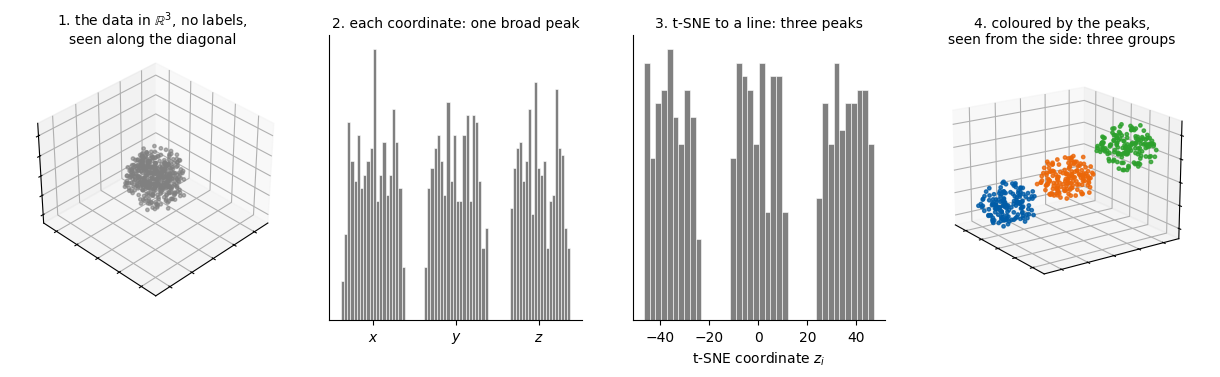

In [15]:
def ball(key, n, r=1.0):
    k1, k2 = jax.random.split(key)
    v = jax.random.normal(k1, (n, 3)); v = v / jnp.linalg.norm(v, axis=1, keepdims=True)
    return v * r * jax.random.uniform(k2, (n, 1)) ** (1 / 3)

diag = jnp.ones(3) / jnp.sqrt(3.0)
keys3 = jax.random.split(section_key(5), 3)
X3 = jnp.concatenate([ball(keys3[k], 150) + (k - 1) * 2.4 * diag for k in range(3)])
g3 = np.repeat(np.arange(3), 150)                     # the true groups: used only to check the result

t = time.time()
Y1, kl1, _ = tsne(X3, d=1, perplexity=30.0)
Y1 = np.asarray(Y1[:, 0]); print(f"t-SNE of 450 points to d = 1: {time.time() - t:.1f} s (including compilation)")

# groups found on the line: cut at the two largest gaps between neighbouring points
order1 = np.argsort(Y1); gaps = np.diff(Y1[order1])
cuts = np.sort(np.argsort(gaps)[-2:])
found = np.zeros(len(Y1), int)
for c in cuts: found[order1[c + 1:]] += 1
purity = np.mean([np.bincount(g3[found == f], minlength=3).max() / (found == f).sum() for f in range(3)])
print(f"two largest gaps on the line: {np.round(np.sort(gaps)[-2:], 1)}  (median gap {np.median(gaps):.2f})")
print(f"each group found on the line contains points of a single true group: purity {purity:.3f}")
nums["tsne_line_purity"] = round(float(purity), 3)

X3n = np.asarray(X3); cols3 = [blue, orange, green]
fig = plt.figure(figsize=(15, 3.7))
a = fig.add_subplot(1, 4, 1, projection="3d")
a.scatter(*X3n.T, s=6, color="grey", alpha=0.6); a.view_init(elev=35.26, azim=45)   # looking along the diagonal (1,1,1)
a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
a.set_title("1. the data in $\\mathbb{R}^3$, no labels,\nseen along the diagonal", fontsize=10)
a = fig.add_subplot(1, 4, 2)
for ax_i, nm in enumerate(["$x$", "$y$", "$z$"]):
    a.hist(X3n[:, ax_i] + 6.0 * ax_i, bins=20, color="grey", edgecolor="white", lw=0.4)
a.set_xticks([0, 6.0, 12.0]); a.set_xticklabels(["$x$", "$y$", "$z$"]); a.set_yticks([]); clean(a)
a.set_title("2. each coordinate: one broad peak", fontsize=10)
a = fig.add_subplot(1, 4, 3)
a.hist(Y1, bins=40, color="grey", edgecolor="white", lw=0.4); a.set_yticks([]); clean(a)
a.set_xlabel("t-SNE coordinate $z_i$"); a.set_title("3. t-SNE to a line: three peaks", fontsize=10)
a = fig.add_subplot(1, 4, 4, projection="3d")
for f in range(3):
    a.scatter(*X3n[found == f].T, s=6, color=cols3[f], alpha=0.8)
a.view_init(elev=18, azim=-35); a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
a.set_title("4. coloured by the peaks,\nseen from the side: three groups", fontsize=10)
fig.tight_layout()
save("gen_tsne_3d_to_line.png"); plt.show()

The three peaks on the line contain the three true groups exactly (purity printed above). t-SNE kept the **neighbours** of every point,
and that was enough to separate groups that no single coordinate and no 3D view showed clearly. What the line does not keep are the
large distances: the gaps between the peaks are not the distances between the groups in 3D. Only "who is next to whom" is meaningful in a
t-SNE map.

t-SNE of 5000 points, d = 2: 131.5 s (including compilation)
final KL(P||Q): 1.335


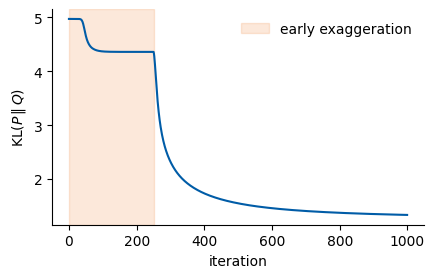

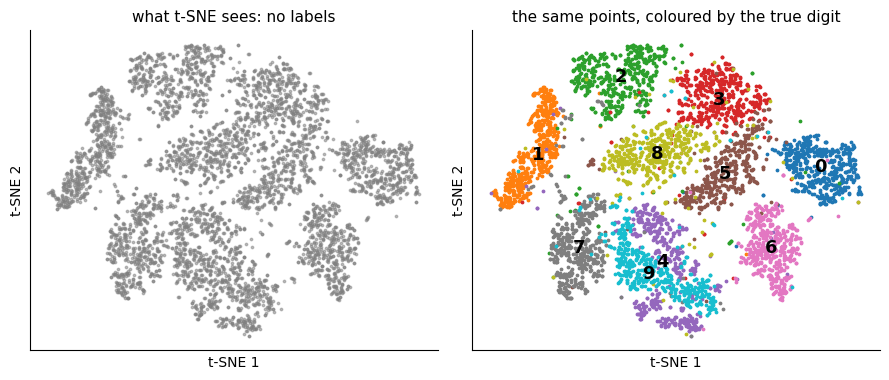

[ 174.1 s] t-SNE 2D done


In [16]:
t = time.time()
E, kl_E, sigma_E = tsne(Z, d=2, perplexity=30.0)
E.block_until_ready(); print(f"t-SNE of 5000 points, d = 2: {time.time() - t:.1f} s (including compilation)")
nums["tsne_mnist_kl_final"] = float(kl_E[-1])
print(f"final KL(P||Q): {nums['tsne_mnist_kl_final']:.3f}")

fig, ax = plt.subplots(figsize=(4.8, 2.8))
ax.plot(np.asarray(kl_E), color=blue)
ax.axvspan(0, 250, color=orange, alpha=0.15, label="early exaggeration")
ax.set_xlabel("iteration"); ax.set_ylabel(r"KL$(P\,\|\,Q)$"); ax.legend(frameon=False); clean(ax)
plt.show()

En = np.asarray(E)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
axs[0].scatter(En[:, 0], En[:, 1], s=3, color="grey", alpha=0.5)
axs[0].set_title("what t-SNE sees: no labels", fontsize=11)
for d in range(10):
    m = y5 == d; axs[1].scatter(En[m, 0], En[m, 1], s=3, color=cmap(d), label=str(d))
    axs[1].text(*np.median(En[m], 0), str(d), fontsize=13, weight="bold", ha="center", va="center")
axs[1].set_title("the same points, coloured by the true digit", fontsize=11)
for a in axs: a.set_xticks([]); a.set_yticks([]); a.set_xlabel("t-SNE 1"); a.set_ylabel("t-SNE 2"); clean(a)
plt.tight_layout(); save("gen_tsne_mnist.png"); plt.show()
log("t-SNE 2D done")

The loss is always evaluated with the true $P$. During early exaggeration it changes little: the exaggerated attractions gather the clusters, but the map is still compact. Once the exaggeration is switched off, the clusters spread out, the loss falls quickly, and then it decreases slowly.

### t-SNE in three dimensions

The same loss with $\mathbf z_i\in\mathbb R^3$; only `d` changes. Two viewing angles of the same map.

/tmp/ipykernel_4070283/51912778.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); save("gen_tsne_mnist_3d.png"); plt.show()


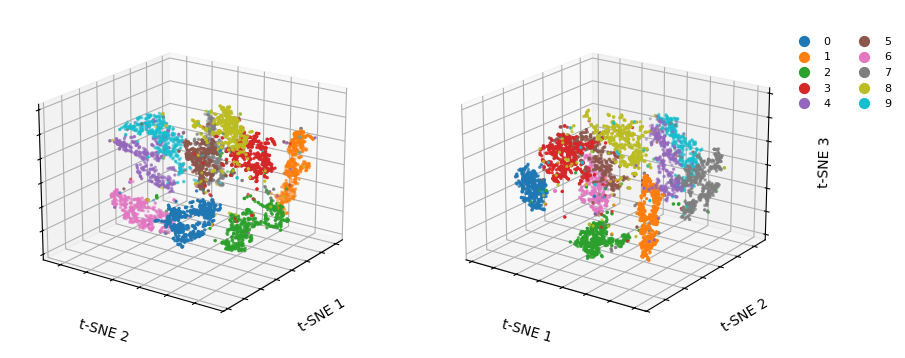

final KL(P||Q): d = 2: 1.335 | d = 3: 1.215
[ 307.6 s] t-SNE 3D done


In [17]:
E3, kl_E3, _ = tsne(Z, d=3, perplexity=30.0)
E3n = np.asarray(E3)
fig = plt.figure(figsize=(10, 4.4))
for k_, (elev, azim) in enumerate([(20, 35), (20, 125)]):
    a = fig.add_subplot(1, 2, k_ + 1, projection="3d")
    for dgt in range(10):
        m = y5 == dgt; a.scatter(E3n[m, 0], E3n[m, 1], E3n[m, 2], s=2, color=cmap(dgt), label=str(dgt))
    a.view_init(elev=elev, azim=azim); a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
    a.set_xlabel("t-SNE 1"); a.set_ylabel("t-SNE 2"); a.set_zlabel("t-SNE 3")
a.legend(markerscale=5, fontsize=8, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 0.95))
plt.tight_layout(); save("gen_tsne_mnist_3d.png"); plt.show()
print(f"final KL(P||Q): d = 2: {float(kl_E[-1]):.3f} | d = 3: {float(kl_E3[-1]):.3f}")
log("t-SNE 3D done")

### The role of the perplexity

The first 2000 of the same digits with three perplexities. Small values keep only very close neighbours (many small fragments); large values smooth the map.

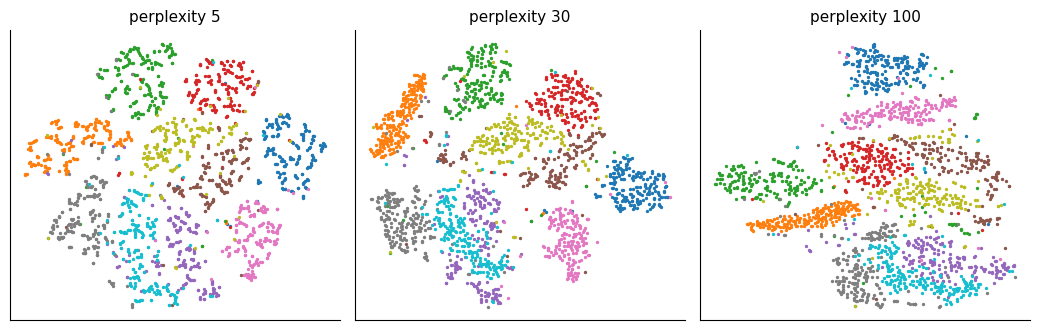

[ 356.2 s] perplexity scan done


In [18]:
Zs, ys = Z[:2000], y5[:2000]
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.4))
for a, pp in zip(axs, [5, 30, 100]):
    Ep, _, _ = tsne(Zs, d=2, perplexity=float(pp))
    Ep = np.asarray(Ep)
    for dgt in range(10):
        m = ys == dgt; a.scatter(Ep[m, 0], Ep[m, 1], s=2, color=cmap(dgt))
    a.set_title(f"perplexity {pp}", fontsize=11); a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); save("gen_tsne_perplexity.png"); plt.show()
log("perplexity scan done")

**What a t-SNE map does not show.**
* *Position of a cluster:* meaningless. The loss depends only on distances between map points, so a rotated, mirrored or shifted map is equally good, and another initialisation puts the clusters elsewhere.
* *Separation between clusters:* carries little meaning. Pairs of distant points have $p_{ij}\approx0$ and barely enter the loss, and the Student-t tail pushes groups apart, so a wide gap does not mean very different data.
* *Cluster sizes:* carry little meaning; $\sigma_i$ adapts to the local density, so dense and sparse groups come out of similar size.
* *Distances inside a cluster:* only the nearest neighbours of each point (about as many as the perplexity) are kept; larger distances are not to scale.

What the map shows reliably is which points are close neighbours. t-SNE places only the points it was given: there is no map for new samples.

**Try it.**
* Rerun `tsne(Z, init="random", key=jax.random.key(1))` and with another key. Which features of the map stay, which change?
* Switch off early exaggeration (`exaggeration=1.0`). How do the final map and the final KL loss change?
* Replace the Student-t kernel by a Gaussian in the map, $w_{ij}=e^{-\lVert\mathbf z_i-\mathbf z_j\rVert^2}$ (this is *symmetric SNE*). Derive the new gradient, check it with `jax.grad`, and look at the crowding of the clusters.
* Run t-SNE on the raw 784 pixels instead of the 50 PCA components. Is the map different? How long does `joint_p` take?

## 4. Clustering

### k-means

k-means splits the samples into $k$ groups $S_1,\dots,S_k$ with centres $\boldsymbol\mu_1,\dots,\boldsymbol\mu_k$ by minimising the total squared distance of the samples to their centres,

$$\mathcal L=\sum_{c=1}^{k}\sum_{i\in S_c}\lVert\mathbf x_i-\boldsymbol\mu_c\rVert^2 .$$

**Lloyd's algorithm** (S. P. Lloyd, IEEE Trans. Inf. Theory **28**, 129 (1982)) alternates two moves until no sample changes cluster:

1. *assign:* every sample joins its nearest centre, $c_i=\arg\min_c\lVert\mathbf x_i-\boldsymbol\mu_c\rVert^2$;
2. *update:* every centre moves to the mean of its samples, $\boldsymbol\mu_c=\frac1{|S_c|}\sum_{i\in S_c}\mathbf x_i$.

Each move can only lower $\mathcal L$: step 1 minimises $\mathcal L$ over the assignments for fixed centres, and step 2 minimises it over the centres for fixed assignments (the mean is the point with the smallest sum of squared distances, $\partial_{\boldsymbol\mu}\sum_{i\in S_c}\lVert\mathbf x_i-\boldsymbol\mu\rVert^2=0$). There are finitely many partitions, so the algorithm stops, but possibly in a poor local minimum. Two remedies are used together:

* **k-means++ initialisation** (D. Arthur and S. Vassilvitskii, SODA 2007): the first centre is a random sample; each next centre is a sample drawn with probability proportional to $D(\mathbf x)^2$, its squared distance to the nearest centre chosen so far. Centres start spread out over the data.
* **Several starts** (here 10), keeping the one with the lowest $\mathcal L$.

JAX idioms in the next cell:
* **`lax.while_loop(cond, body, state)`** repeats `body` while `cond(state)` is true; the number of iterations is decided at run time, inside the compiled program.
* The *update* step uses a one-hot matrix $H_{ic}=[c_i=c]$: the sums of the samples of each cluster are $H^{\top}X$, the counts are the column sums of $H$. One matrix product, no loop over clusters. An empty cluster keeps its old centre.
* **`jax.random.choice(key, n, p=...)`** draws an index with given probabilities (k-means++).
* **`jax.vmap` over keys** runs the 10 independent starts in parallel. `k` is a `static` argument: it fixes the array shapes, so a new `k` compiles a new program.

In [19]:
def sq_dists_xy(X, M):
    # squared distances between the rows of X (n x D) and of M (k x D)
    return jnp.maximum(jnp.sum(X * X, 1)[:, None] + jnp.sum(M * M, 1)[None, :] - 2.0 * X @ M.T, 0.0)

@jax.jit
def assign(X, mu):
    d2 = sq_dists_xy(X, mu)
    return jnp.argmin(d2, axis=1), jnp.min(d2, axis=1)

@partial(jax.jit, static_argnames="k")
def update_centres(X, labels, mu_old, k):
    H = jax.nn.one_hot(labels, k, dtype=X.dtype)                 # n x k
    counts = H.sum(axis=0)
    sums = H.T @ X
    return jnp.where(counts[:, None] > 0, sums / jnp.maximum(counts, 1.0)[:, None], mu_old)

def kmeans_pp_init(key, X, k):
    n = X.shape[0]
    key, sub = jax.random.split(key)
    first = jax.random.randint(sub, (), 0, n)
    mu = jnp.zeros((k, X.shape[1]), X.dtype).at[0].set(X[first])
    d2 = jnp.sum((X - X[first]) ** 2, axis=1)                    # squared distance to the nearest centre
    def body(c, state):
        mu, d2, key = state
        key, sub = jax.random.split(key)
        idx = jax.random.choice(sub, n, p=d2 / d2.sum())
        return mu.at[c].set(X[idx]), jnp.minimum(d2, jnp.sum((X - X[idx]) ** 2, axis=1)), key
    mu, _, _ = lax.fori_loop(1, k, body, (mu, d2, key))
    return mu

def lloyd(X, mu0, max_iter=300):
    k = mu0.shape[0]
    def cond(state):
        _, _, changed, it = state
        return changed & (it < max_iter)
    def body(state):
        mu, labels, _, it = state
        mu = update_centres(X, labels, mu, k)
        new_labels, _ = assign(X, mu)
        return mu, new_labels, jnp.any(new_labels != labels), it + 1
    labels0, _ = assign(X, mu0)
    mu, labels, _, n_it = lax.while_loop(cond, body, (mu0, labels0, jnp.array(True), jnp.int32(0)))
    return mu, labels, jnp.sum(assign(X, mu)[1]), n_it

@partial(jax.jit, static_argnames=("k", "n_init", "max_iter"))
def kmeans(key, X, k, n_init=10, max_iter=300):
    # best of n_init k-means++ starts: centres, labels, loss L, number of Lloyd iterations
    def one_start(kk):
        return lloyd(X, kmeans_pp_init(kk, X, k), max_iter)
    mus, labels, losses, iters = jax.vmap(one_start)(jax.random.split(key, n_init))
    best = jnp.argmin(losses)
    return mus[best], labels[best], losses[best], iters[best]

### k-means, iteration by iteration

Three groups of 100 points in 2D. To see the algorithm work, the three centres start badly on purpose: all three inside the same group (lower right). The panels show the start, the first two iterations and the final state; colours are the current assignment, crosses the centres. The printout lists the loss after every iteration.

loss at the start and after each iteration: [9424.  3570.1 2812.3 1103.2  761.3]
iteration 4 changes no assignment: converged


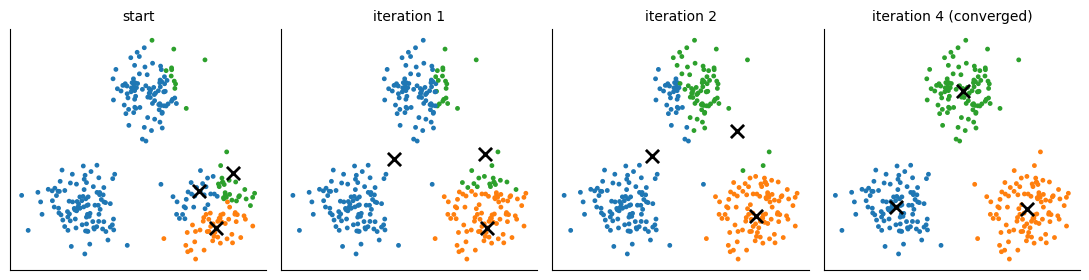

In [20]:
def make_blobs(key, n_per, centres, std):
    centres = jnp.asarray(centres, jnp.float32)
    pts = centres[:, None, :] + std * jax.random.normal(key, (len(centres), n_per, centres.shape[1]))
    return pts.reshape(-1, centres.shape[1]), np.repeat(np.arange(len(centres)), n_per)

Xb, _ = make_blobs(section_key(6), 100, [[-4.0, -2.0], [4.0, -2.0], [0.0, 4.5]], 1.1)
mu = jnp.array([[3.0, -1.0], [4.0, -3.0], [5.0, 0.0]])          # a poor start: all three centres in one group
history = [(mu, assign(Xb, mu)[0])]
losses = [float(jnp.sum(assign(Xb, mu)[1]))]
while True:                                       # one iteration = update, then assign
    mu = update_centres(Xb, history[-1][1], mu, 3)
    lab, d2 = assign(Xb, mu)
    losses.append(float(d2.sum()))
    history.append((mu, lab))
    if bool(jnp.all(lab == history[-2][1])):
        break
nums["kmeans_iter_toy_n_iter"] = len(history) - 1
print("loss at the start and after each iteration:", np.round(losses, 1))
print("iteration", nums["kmeans_iter_toy_n_iter"], "changes no assignment: converged")

panels = [0, 1, 2, len(history) - 1] if len(history) > 4 else list(range(len(history)))
Xbn = np.asarray(Xb)
fig, axs = plt.subplots(1, len(panels), figsize=(11, 2.9))
for a, it in zip(axs, panels):
    mu_, lab_ = history[it]; mu_ = np.asarray(mu_)
    a.scatter(Xbn[:, 0], Xbn[:, 1], s=6, c=cmap(np.asarray(lab_)))
    a.scatter(mu_[:, 0], mu_[:, 1], marker="x", s=90, color="k", lw=2)
    title = "start" if it == 0 else f"iteration {it}"
    if it == len(history) - 1 and it > 0: title += " (converged)"
    a.set_title(title, fontsize=10); a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); save("gen_kmeans_iterations.png"); plt.show()

### The silhouette score

In a good clustering each sample is close to its own cluster and far from the others (P. J. Rousseeuw, J. Comput. Appl. Math. **20**, 53 (1987)). For a sample $\mathbf x_i$ in cluster $S_c$:

$$a_i=\frac{1}{|S_c|-1}\sum_{j\in S_c,\,j\ne i}\lVert\mathbf x_i-\mathbf x_j\rVert,\qquad b_i=\min_{c'\ne c}\frac{1}{|S_{c'}|}\sum_{j\in S_{c'}}\lVert\mathbf x_i-\mathbf x_j\rVert,\qquad s_i=\frac{b_i-a_i}{\max(a_i,b_i)}\in[-1,1].$$

$s_i\approx1$: well inside its cluster; $s_i\approx0$: on the border between two clusters; $s_i<0$: closer to another cluster. For a cluster with a single sample $s_i=0$ by convention. The mean $\bar s=\frac1n\sum_is_i$ scores the whole clustering.

In JAX all mean distances to all clusters come from one product: with the distance matrix $D_{ij}$ and the one-hot matrix $H$, $(DH)_{ic}$ is the sum of distances from $i$ to the members of $c$.

The sketch shows the two distances for one point.

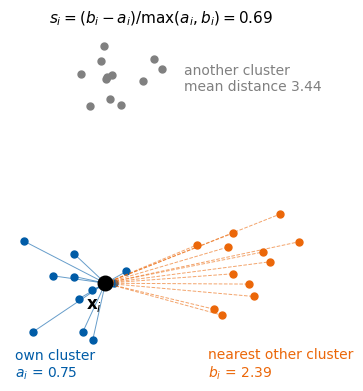

{'a_i': 0.75, 'b_i': 2.39, 's_i': 0.69}


In [21]:
@partial(jax.jit, static_argnames="k")
def silhouette_samples(D, labels, k):
    # s_i for every sample, from the matrix of (not squared) distances D
    n = D.shape[0]
    H = jax.nn.one_hot(labels, k, dtype=D.dtype)
    counts = H.sum(axis=0)
    sums = D @ H                                           # sum of distances from i to each cluster
    own = counts[labels]
    a = sums[jnp.arange(n), labels] / jnp.maximum(own - 1.0, 1.0)
    mean_other = jnp.where((H > 0) | (counts[None, :] == 0), jnp.inf, sums / jnp.maximum(counts, 1.0)[None, :])
    b = mean_other.min(axis=1)
    return jnp.where(own > 1, (b - a) / jnp.maximum(a, b), 0.0)

def silhouette(D, labels, k):
    return float(silhouette_samples(D, labels, k).mean())

k1, k2, k3 = jax.random.split(section_key(8), 3)
own  = np.asarray(jnp.array([0.0, 0.0]) + 0.45 * jax.random.normal(k1, (12, 2)))   # the cluster of point i
near = np.asarray(jnp.array([3.0, 0.3]) + 0.45 * jax.random.normal(k2, (12, 2)))   # the nearest other cluster
far  = np.asarray(jnp.array([0.8, 3.6]) + 0.45 * jax.random.normal(k3, (12, 2)))   # another cluster
xi = np.array([0.6, 0.2]); others = own[1:]
a_i = np.linalg.norm(others - xi, axis=1).mean()
b_near = np.linalg.norm(near - xi, axis=1).mean(); b_far = np.linalg.norm(far - xi, axis=1).mean()
b_i = min(b_near, b_far); s_i = (b_i - a_i) / max(a_i, b_i)
nums["silhouette_sketch"] = {"a_i": round(float(a_i), 2), "b_i": round(float(b_i), 2), "s_i": round(float(s_i), 2)}

fig, ax = plt.subplots(figsize=(5.2, 4.2))
for q in others: ax.plot([xi[0], q[0]], [xi[1], q[1]], color=blue, lw=0.7, alpha=0.6)
for q in near:   ax.plot([xi[0], q[0]], [xi[1], q[1]], color=orange, lw=0.7, alpha=0.6, ls="--")
ax.scatter(*others.T, s=25, color=blue); ax.scatter(*near.T, s=25, color=orange); ax.scatter(*far.T, s=25, color="grey")
ax.scatter(*xi, s=110, color="k", zorder=5)
ax.annotate(r"$\mathbf{x}_i$", xi, xytext=(-14, -18), textcoords="offset points", fontsize=12)
ax.text(-0.9, -1.35, f"own cluster\n$a_i$ = {a_i:.2f}", color=blue, fontsize=10)
ax.text(2.3, -1.35, f"nearest other cluster\n$b_i$ = {b_i:.2f}", color=orange, fontsize=10)
ax.text(1.9, 3.4, f"another cluster\nmean distance {b_far:.2f}", color="grey", fontsize=10)
ax.set_title(rf"$s_i = (b_i - a_i)/\max(a_i, b_i) = {s_i:.2f}$", fontsize=11)
ax.set_aspect("equal"); ax.axis("off")
save("gen_silhouette_sketch.png"); plt.show()
print(nums["silhouette_sketch"])

### Choosing $k$

k-means needs $k$ from us. Two common guides:

* the **elbow**: the loss $\mathcal L(k)$ always decreases when $k$ grows (more centres, shorter distances); look for the $k$ after which it decreases only slowly;
* the **silhouette**: pick the $k$ with the largest $\bar s(k)$.

The procedure: for every $k=2,\dots,8$ run k-means (10 starts, keep the lowest loss), record $\mathcal L(k)$ and $\bar s(k)$, and plot both against $k$. The data: four Gaussian groups of 150 points, so the right answer is known. The dotted line marks $k=4$, drawn only for comparison.

k:          [2, 3, 4, 5, 6, 7, 8]
loss:       [7275. 3812. 1206. 1084.  965.  847.  753.]
silhouette: [0.477 0.561 0.692 0.599 0.522 0.435 0.346]
largest silhouette at k = 4


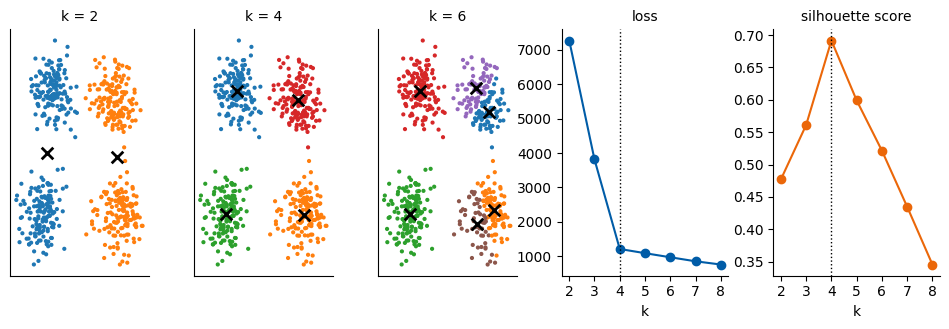

In [22]:
Xk, yk = make_blobs(section_key(9), 150, [[-4.0, -3.0], [-3.0, 3.5], [3.0, 3.0], [3.5, -3.0]], 1.0)
Dk = jnp.sqrt(sq_dists(Xk))
ks4 = list(range(2, 9)); loss4, sil4, fits4 = [], [], {}
for kk in ks4:
    mu_, lab_, L_, _ = kmeans(section_key(10), Xk, kk)
    loss4.append(float(L_)); sil4.append(silhouette(Dk, lab_, kk)); fits4[kk] = (np.asarray(mu_), np.asarray(lab_))
nums["toy4_best_k_silhouette"] = int(ks4[int(np.argmax(sil4))])
nums["toy4_silhouette"] = [round(s_, 3) for s_ in sil4]
print("k:         ", ks4); print("loss:      ", np.round(loss4, 0)); print("silhouette:", np.round(sil4, 3))
print("largest silhouette at k =", nums["toy4_best_k_silhouette"])

Xkn = np.asarray(Xk)
fig = plt.figure(figsize=(12, 3.2)); gsk = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1.2, 1.2], wspace=0.3)
for j, kk in enumerate([2, 4, 6]):
    a = fig.add_subplot(gsk[0, j]); cen_, lab_ = fits4[kk]
    a.scatter(Xkn[:, 0], Xkn[:, 1], s=4, c=cmap(lab_)); a.scatter(cen_[:, 0], cen_[:, 1], marker="x", s=70, color="k", lw=2)
    a.set_title(f"k = {kk}", fontsize=10); a.set_xticks([]); a.set_yticks([]); clean(a)
a = fig.add_subplot(gsk[0, 3]); a.plot(ks4, loss4, "o-", color=blue); a.axvline(4, color="k", ls=":", lw=1)
a.set_title("loss", fontsize=10); a.set_xlabel("k"); a.set_xticks(ks4); clean(a)
a = fig.add_subplot(gsk[0, 4]); a.plot(ks4, sil4, "o-", color=orange); a.axvline(4, color="k", ls=":", lw=1)
a.set_title("silhouette score", fontsize=10); a.set_xlabel("k"); a.set_xticks(ks4); clean(a)
save("gen_kmeans_choose_k_toy.png"); plt.show()

### Rand index and adjusted Rand index

To score a clustering against known classes we compare two partitions of the same $n$ samples, **pair by pair**; the names of the groups do not matter. A pair *agrees* if both partitions put it in the same group, or both put it in different groups. The **Rand index** is the fraction of agreeing pairs among all $\binom n2$.

Everything follows from the **contingency table** $n_{uv}$ = number of samples in class $u$ and cluster $v$, with row sums $a_u$ and column sums $b_v$:

$$\underbrace{\sum_{uv}\tbinom{n_{uv}}2}_{\text{same, same}},\qquad
\underbrace{\tbinom n2-\sum_u\tbinom{a_u}2-\sum_v\tbinom{b_v}2+\sum_{uv}\tbinom{n_{uv}}2}_{\text{different, different}},\qquad
\mathrm{RI}=\frac{\text{sum of the two}}{\binom n2}.$$

Random groups already agree on many pairs (most pairs are apart in both partitions), so the index is corrected for chance (L. Hubert and P. Arabie, J. Classification **2**, 193 (1985)):

$$\mathrm{ARI}=\frac{\mathrm{RI}-\mathbb E[\mathrm{RI}]}{1-\mathbb E[\mathrm{RI}]}
=\frac{\sum_{uv}\binom{n_{uv}}2-\big[\sum_u\binom{a_u}2\sum_v\binom{b_v}2\big]\big/\binom n2}
{\tfrac12\big[\sum_u\binom{a_u}2+\sum_v\binom{b_v}2\big]-\big[\sum_u\binom{a_u}2\sum_v\binom{b_v}2\big]\big/\binom n2},$$

where $\mathbb E[\mathrm{RI}]$ is the mean over random relabellings that keep all group sizes. ARI = 1 for identical partitions, about 0 for random ones, and it can be negative.

In JAX the contingency table is again a product of one-hot matrices, $N=H_a^{\top}H_b$. Labels are first renumbered $0,\dots,K-1$ (`np.unique(..., return_inverse=True)`), so that DBSCAN's noise label $-1$ simply becomes one more group.

true groups    : RI 1.000, ARI +1.000
k-means, k = 4 : RI 0.998, ARI +0.996
k-means, k = 2 : RI 0.748, ARI +0.495
random groups  : RI 0.626, ARI +0.001


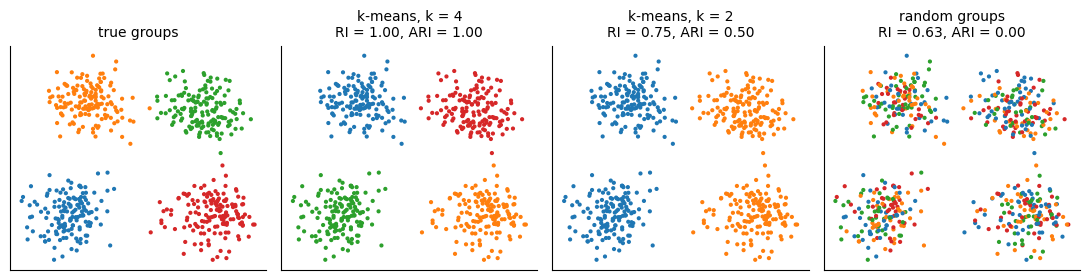

In [23]:
@partial(jax.jit, static_argnames=("ka", "kb"))
def _rand_indices(a, b, ka, kb):
    N = jax.nn.one_hot(a, ka).T @ jax.nn.one_hot(b, kb)             # contingency table
    comb2 = lambda x: x * (x - 1.0) / 2.0
    n = a.shape[0]
    s_ab, s_a, s_b, total = comb2(N).sum(), comb2(N.sum(1)).sum(), comb2(N.sum(0)).sum(), comb2(jnp.float32(n))
    ri = (total + 2.0 * s_ab - s_a - s_b) / total
    expected = s_a * s_b / total
    ari = (s_ab - expected) / (0.5 * (s_a + s_b) - expected)
    return ri, ari

def rand_indices(a, b):
    # (RI, ARI) of two labellings of the same samples
    ua, a_ = np.unique(np.asarray(a), return_inverse=True)
    ub, b_ = np.unique(np.asarray(b), return_inverse=True)
    ri, ari = _rand_indices(jnp.asarray(a_), jnp.asarray(b_), len(ua), len(ub))
    return float(ri), float(ari)

# the four groups of the previous cell: true groups and three clusterings
parts = [("true groups", yk),
         ("k-means, k = 4", fits4[4][1]),
         ("k-means, k = 2", fits4[2][1]),
         ("random groups", np.asarray(jax.random.randint(section_key(11), (len(yk),), 0, 4)))]
fig, axs = plt.subplots(1, 4, figsize=(11, 2.9))
for a, (title, lab) in zip(axs, parts):
    ri, ari = rand_indices(yk, lab)
    a.scatter(Xkn[:, 0], Xkn[:, 1], s=4, c=cmap(lab)); a.set_xticks([]); a.set_yticks([]); clean(a)
    a.set_title(title if title == "true groups" else f"{title}\nRI = {ri:.2f}, ARI = {ari:.2f}", fontsize=10)
    print(f"{title:15s}: RI {ri:.3f}, ARI {ari:+.3f}")
plt.tight_layout(); save("gen_ari_toy.png"); plt.show()
for key_, (_, lab) in zip(["k4", "k2", "random"], parts[1:]):
    ri, ari = rand_indices(yk, lab)
    nums[f"ari_toy_{key_}"] = {"RI": round(ri, 3), "ARI": round(ari, 3)}

### k-means on MNIST

We ask for $k=10$ groups, once on the 50 PCA components and once on the t-SNE map, and compare them with the true digits by the ARI. The ten centres found on the PCA components can be mapped back to pixels, $\bar{\mathbf x}+\sum_{a\le50}\mu_a\mathbf v_a$, and shown as images.

k-means, k = 10: ARI on 50 PCA components 0.380 (42 Lloyd iterations) | on the t-SNE map 0.757 (38 Lloyd iterations)


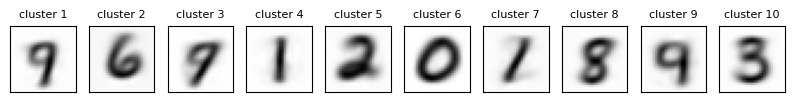

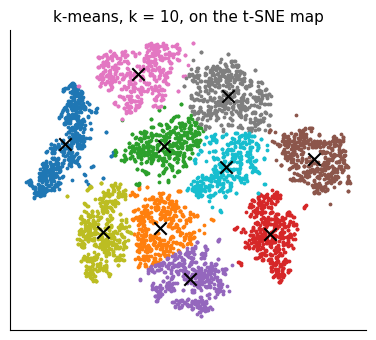

t-SNE clusters, rows = true digit, columns = cluster:
 [[  0   0   1   3   0 489   0   0   0   4]
 [528   0   2   1   0   0   4   0   0   0]
 [  7   0   7   6   0   3 507   4  12   1]
 [  1   2  11   1   1   2   5 473   2   3]
 [  6 212   1   4 227   0   0   0   2   0]
 [  6   4   7   4   1   6   0  51   2 366]
 [  0   0   0 472   1   5   0   0   0   3]
 [ 28   3   0   0  10   0   7   0 476   0]
 [  2  11 412   0   6   3   4  27   3  42]
 [  1 233   4   1 240   1   1   6  15   4]]


In [24]:
mu_Z, lab_Z, loss_Z, it_Z = kmeans(section_key(12), Z, 10)
mu_E, lab_E, loss_E, it_E = kmeans(section_key(12), E, 10)
nums["kmeans_ari_pca50"] = rand_indices(y5, lab_Z)[1]
nums["kmeans_ari_tsne"] = rand_indices(y5, lab_E)[1]
print(f"k-means, k = 10: ARI on 50 PCA components {nums['kmeans_ari_pca50']:.3f} ({int(it_Z)} Lloyd iterations)"
      f" | on the t-SNE map {nums['kmeans_ari_tsne']:.3f} ({int(it_E)} Lloyd iterations)")

cent = np.asarray(xbar + mu_Z @ V[:, :50].T)
fig, axs = plt.subplots(1, 10, figsize=(10, 1.3))
for k_, a in enumerate(axs):
    a.imshow(cent[k_].reshape(28, 28), cmap="gray_r"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"cluster {k_ + 1}", fontsize=8)
save("gen_kmeans_centroids.png"); plt.show()

lab_En, mu_En = np.asarray(lab_E), np.asarray(mu_E)
fig, ax = plt.subplots(figsize=(4.6, 3.9))
for k_ in range(10):
    m = lab_En == k_; ax.scatter(En[m, 0], En[m, 1], s=3, color=cmap(k_))
ax.scatter(*mu_En.T, marker="x", s=80, color="k")
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("k-means, k = 10, on the t-SNE map", fontsize=11); clean(ax)
save("gen_kmeans_tsne.png"); plt.show()

# which digits end up in which cluster (contingency table: rows = digits, columns = clusters)
N_tab = np.zeros((10, 10), int); np.add.at(N_tab, (y5, lab_En), 1)
print("t-SNE clusters, rows = true digit, columns = cluster:\n", N_tab)

### Choosing $k$ on MNIST

The same two guides on the t-SNE map of the 5000 digits, for $k=2,\dots,15$, with the exact silhouette over all 5000 points (one $5000\times5000$ distance matrix, computed once). The dotted line marks $k=10$, the number of digits; it is drawn only for comparison, k-means and the two guides do not know the labels.

k:          [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
silhouette: [0.344 0.411 0.409 0.399 0.396 0.421 0.459 0.471 0.468 0.47  0.468 0.448
 0.44  0.427]
largest silhouette at k = 9


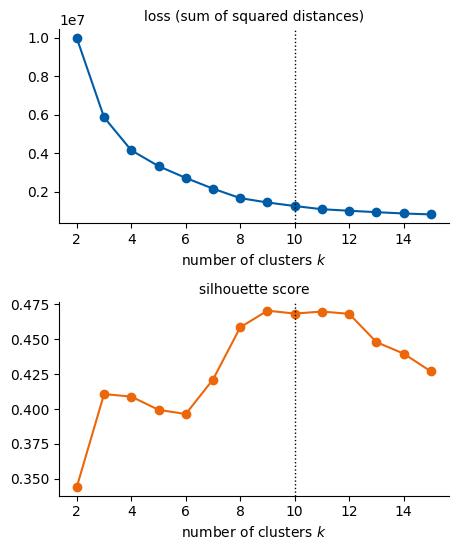

[ 399.7 s] k-means done


In [25]:
DE = jnp.sqrt(sq_dists_lowdim(E))
ks = list(range(2, 16)); loss_k, sil_k = [], []
for kk in ks:
    _, lab_, L_, _ = kmeans(section_key(13), E, kk)
    loss_k.append(float(L_)); sil_k.append(silhouette(DE, lab_, kk))
nums["kmeans_best_k_silhouette"] = int(ks[int(np.argmax(sil_k))])
nums["kmeans_silhouette_k10"] = round(sil_k[ks.index(10)], 3)
print("k:         ", ks); print("silhouette:", np.round(sil_k, 3))
print("largest silhouette at k =", nums["kmeans_best_k_silhouette"])

fig, axs = plt.subplots(2, 1, figsize=(4.6, 5.6))
axs[0].plot(ks, loss_k, "o-", color=blue); axs[0].set_title("loss (sum of squared distances)", fontsize=10)
axs[1].plot(ks, sil_k, "o-", color=orange); axs[1].set_title("silhouette score", fontsize=10)
for a in axs: a.set_xlabel("number of clusters $k$"); a.axvline(10, color="k", ls=":", lw=1); clean(a)
plt.tight_layout(); save("gen_kmeans_choose_k.png"); plt.show()
log("k-means done")

### Limits of k-means, and DBSCAN

k-means cuts space into convex cells around the centres, so it finds round clusters. **DBSCAN** (M. Ester, H.-P. Kriegel, J. Sander, X. Xu, KDD 1996) instead grows clusters from dense regions. It has two parameters, a radius $\varepsilon$ and a minimum number of points $m$:

* a **core point** has at least $m$ points (itself included) within distance $\varepsilon$;
* a **border point** is not a core point but lies within $\varepsilon$ of one;
* every other point is **noise**.

A cluster is a set of core points that can be reached from each other in steps shorter than $\varepsilon$, together with their border points. The algorithm:

1. count the neighbours within $\varepsilon$ of every point and mark the core points;
2. take a core point not yet in a cluster and start a new cluster with it;
3. add every point within $\varepsilon$ of a core point of the cluster; repeat until no point is added (a breadth-first search; border points join but do not expand the cluster);
4. repeat 2–3 until every core point is in a cluster; the points never reached are noise.

DBSCAN needs no number of clusters, follows clusters of any shape and leaves isolated points unassigned. The neighbour matrix is computed in JAX; the search itself is a short Python loop over a queue, which is easier to read than a compiled version and fast enough for a few thousand points.

Two half-moons, the classic case where k-means fails, are generated below: points on two interlocking half-circles plus Gaussian noise.

{'clusters': 3, 'core': 65, 'border': 6, 'noise': 7}


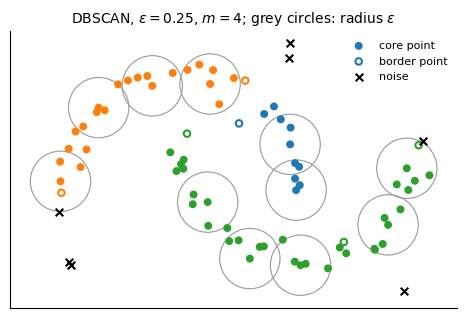

In [26]:
def dbscan(X, eps, min_pts):
    # labels (-1 = noise) and the core-point mask
    nb = np.asarray(sq_dists(jnp.asarray(X)) <= eps ** 2)        # neighbour matrix, itself included
    core = nb.sum(axis=1) >= min_pts
    labels = np.full(len(nb), -1)
    c = 0
    for i in np.flatnonzero(core):
        if labels[i] != -1:
            continue
        labels[i] = c; queue = deque([i])
        while queue:                                              # breadth-first search from core point i
            j = queue.popleft()
            if not core[j]:
                continue                                          # border points do not expand the cluster
            for q in np.flatnonzero(nb[j]):
                if labels[q] == -1:
                    labels[q] = c; queue.append(q)
        c += 1
    return labels, core

def make_moons(key, n, noise):
    n_out = n // 2; n_in = n - n_out
    t_out, t_in = jnp.linspace(0, jnp.pi, n_out), jnp.linspace(0, jnp.pi, n_in)
    X = jnp.concatenate([jnp.stack([jnp.cos(t_out), jnp.sin(t_out)], 1),
                         jnp.stack([1 - jnp.cos(t_in), 0.5 - jnp.sin(t_in)], 1)])
    return X + noise * jax.random.normal(key, X.shape), np.r_[np.zeros(n_out, int), np.ones(n_in, int)]

k1, k2 = jax.random.split(section_key(14))
Xd = np.r_[np.asarray(make_moons(k1, 70, 0.07)[0]),
           np.asarray(jax.random.uniform(k2, (8, 2), minval=jnp.array([-1.2, -0.8]), maxval=jnp.array([2.2, 1.3])))]
eps_d, m_d = 0.25, 4
lab_d, core = dbscan(Xd, eps_d, m_d)
noise_d = lab_d == -1; border = ~core & ~noise_d
nums["dbscan_sketch"] = {"clusters": int(lab_d.max() + 1), "core": int(core.sum()), "border": int(border.sum()), "noise": int(noise_d.sum())}
print(nums["dbscan_sketch"])

fig, ax = plt.subplots(figsize=(6.2, 3.6))
for i in np.flatnonzero(core)[::6]:
    ax.add_patch(plt.Circle(Xd[i], eps_d, fill=False, color="#999999", lw=0.8))
ax.scatter(*Xd[core].T, s=22, c=cmap(lab_d[core]), label="core point")
ax.scatter(*Xd[border].T, s=22, facecolors="white", edgecolors=cmap(lab_d[border]), lw=1.5, label="border point")
ax.scatter(*Xd[noise_d].T, s=30, marker="x", color="k", label="noise")
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.legend(frameon=False, fontsize=8, loc="upper right"); clean(ax)
ax.set_title(rf"DBSCAN, $\varepsilon = {eps_d}$, $m = {m_d}$; grey circles: radius $\varepsilon$", fontsize=10)
save("gen_dbscan_sketch.png"); plt.show()

{'moons_ari_kmeans': 0.241, 'moons_ari_dbscan': 1.0, 'moons_dbscan_clusters': 2, 'moons_dbscan_noise': 0}


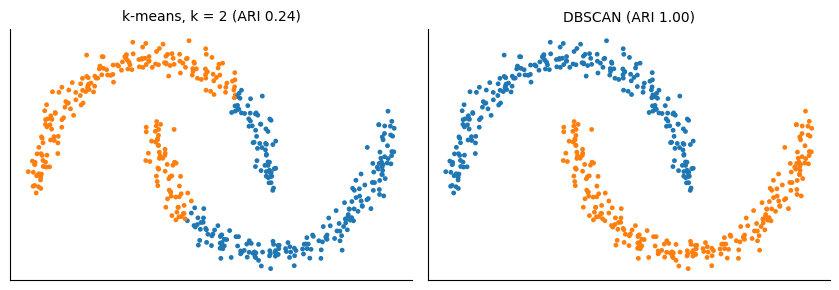

In [27]:
Xm, ym = make_moons(section_key(15), 500, 0.06)
_, lab_km, _, _ = kmeans(section_key(16), Xm, 2)
lab_db, _ = dbscan(Xm, 0.2, 5)
nums["moons_ari_kmeans"] = rand_indices(ym, lab_km)[1]
nums["moons_ari_dbscan"] = rand_indices(ym, lab_db)[1]
nums["moons_dbscan_clusters"] = int(lab_db.max() + 1); nums["moons_dbscan_noise"] = int((lab_db == -1).sum())
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in nums.items() if k.startswith("moons")})

Xmn = np.asarray(Xm)
fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.0))
for a, lab, title in zip(axs, [np.asarray(lab_km), lab_db],
                         [f"k-means, k = 2 (ARI {nums['moons_ari_kmeans']:.2f})", f"DBSCAN (ARI {nums['moons_ari_dbscan']:.2f})"]):
    cols = np.where((lab >= 0)[:, None], cmap(lab % 10), np.array([[0.5, 0.5, 0.5, 1.0]]))
    a.scatter(Xmn[:, 0], Xmn[:, 1], s=6, c=cols); a.set_title(title, fontsize=10)
    a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); save("gen_kmeans_moons.png"); plt.show()

**Try it.**
* Run k-means with $k=5$ and $k=15$ on the t-SNE map. Which digits are merged, which are split? Use the contingency table.
* Replace k-means++ by a uniformly random choice of the initial centres and use `n_init=1`. How often does the toy example with four groups end in a poor local minimum? Run it for 100 keys with `jax.vmap`.
* Run DBSCAN on the t-SNE map of the digits. Find $\varepsilon$ and $m$ that give about ten clusters, and compare the ARI (on the non-noise points) with k-means.
* Compute the silhouette for k-means with $k=2$ on the half-moons, and for DBSCAN. Which clustering does the silhouette prefer, and why is that misleading here?

## Optional: cross-check with scikit-learn

Our implementations follow the textbook definitions. As an independent check, the same quantities from scikit-learn (if installed): the adjusted Rand and Rand indices of the same labellings, the mean silhouette of the same clusterings, the k-means loss found by `sklearn.cluster.KMeans`, and DBSCAN on the half-moons. scikit-learn is used **only** here.

In [28]:
try:
    from sklearn.metrics import adjusted_rand_score, rand_score, silhouette_score
    from sklearn.cluster import KMeans, DBSCAN
    print("ARI on 50 PCA components:  ours", round(nums["kmeans_ari_pca50"], 6), "| sklearn", round(adjusted_rand_score(y5, np.asarray(lab_Z)), 6))
    print("ARI on the t-SNE map:      ours", round(nums["kmeans_ari_tsne"], 6), "| sklearn", round(adjusted_rand_score(y5, lab_En), 6))
    r_lab = parts[3][1]
    print("RI of the random groups:   ours", round(rand_indices(yk, r_lab)[0], 6), "| sklearn", round(rand_score(yk, r_lab), 6))
    print("silhouette, toy, k = 4:    ours", round(sil4[2], 6), "| sklearn", round(silhouette_score(Xkn, fits4[4][1]), 6))
    _, lab10, _, _ = kmeans(section_key(13), E, 10)
    print("silhouette, MNIST, k = 10: ours", round(silhouette(DE, lab10, 10), 6), "| sklearn", round(silhouette_score(En, np.asarray(lab10)), 6))
    sk = KMeans(10, n_init=10, random_state=0).fit(Zn)
    print("k-means loss on 50 PCA comp.: ours", round(float(loss_Z), 1), "| sklearn", round(sk.inertia_, 1),
          "| ARI between the two partitions", round(adjusted_rand_score(sk.labels_, np.asarray(lab_Z)), 3))
    sk_db = DBSCAN(eps=0.2, min_samples=5).fit_predict(Xmn)
    print("DBSCAN on the half-moons: ARI between ours and sklearn's labels", round(adjusted_rand_score(sk_db, lab_db), 6))
except ImportError:
    print("scikit-learn is not installed; cross-check skipped")

ARI on 50 PCA components:  ours 0.380302 | sklearn 0.380302
ARI on the t-SNE map:      ours 0.757295 | sklearn 0.757295
RI of the random groups:   ours 0.626294 | sklearn 0.626294
silhouette, toy, k = 4:    ours 0.691623 | sklearn 0.691623


silhouette, MNIST, k = 10: ours 0.468421 | sklearn 0.468421


k-means loss on 50 PCA comp.: ours 150274.5 | sklearn 150262.8 | ARI between the two partitions 0.93
DBSCAN on the half-moons: ARI between ours and sklearn's labels 1.0


## Numbers used on the slides

All numbers quoted on the lecture slides for this part, written to `../beamer/figures/numbers_lab016.json`.

In [29]:
with open(f"{OUT}/numbers_lab016.json", "w") as f:
    json.dump(nums, f, indent=1)
print(json.dumps(nums, indent=1))
log("notebook finished")

{
 "pca_toy_var": [
  0.934,
  0.066
 ],
 "mnist_pca_var2": 0.16800589859485626,
 "mnist_pca_var3": 0.22969676554203033,
 "mnist_pca_var10": 0.4881497323513031,
 "mnist_pca_var50": 0.8246467709541321,
 "mnist_pca_frac_2_10_50": [
  0.168,
  0.488,
  0.825
 ],
 "mnist_pca_k_for_90": 87,
 "tsne_line_purity": 1.0,
 "tsne_mnist_kl_final": 1.3347938060760498,
 "kmeans_iter_toy_n_iter": 4,
 "silhouette_sketch": {
  "a_i": 0.75,
  "b_i": 2.39,
  "s_i": 0.69
 },
 "toy4_best_k_silhouette": 4,
 "toy4_silhouette": [
  0.477,
  0.561,
  0.692,
  0.599,
  0.522,
  0.435,
  0.346
 ],
 "ari_toy_k4": {
  "RI": 0.998,
  "ARI": 0.996
 },
 "ari_toy_k2": {
  "RI": 0.748,
  "ARI": 0.495
 },
 "ari_toy_random": {
  "RI": 0.626,
  "ARI": 0.001
 },
 "kmeans_ari_pca50": 0.38030219078063965,
 "kmeans_ari_tsne": 0.7572949528694153,
 "kmeans_best_k_silhouette": 9,
 "kmeans_silhouette_k10": 0.468,
 "dbscan_sketch": {
  "clusters": 3,
  "core": 65,
  "border": 6,
  "noise": 7
 },
 "moons_ari_kmeans": 0.2405420988798